## Synthetic Dataset Generation & Exploratory Correlation Analysis

To rigorously test our regression algorithms in a high-dimensional setting, we generate a synthetic dataset using `sklearn.datasets.make_regression`. The resulting feature matrix $X$ comprises 500 observations across 100 features, paired with a continuous target vector $y$.

### Feature Selection via Pearson Correlation
By default, `make_regression` constructs a sparse underlying linear model where only a small subset of features (typically 10) actually contributes to the target variable, while the remaining 90 dimensions consist entirely of uninformative Gaussian noise. Plotting arbitrary columns would merely display featureless point clouds.

To isolate and inspect the true signal in the data, we perform a correlation-based exploratory analysis:
* **Correlation Ranking:** We compute the Pearson correlation coefficient (`np.corrcoef`) between each of the 100 columns and the target $y$, sorting them by their absolute magnitude to identify the most influential predictors.
* **Visualizing Informative Predictors:** The scatter plots display the top 3 most correlated features (such as Features 34, 91, and 38, exhibiting correlations of $r \approx 0.54 - 0.58$). Unlike noisy dimensions, these subplots reveal clear positive linear trends, confirming the underlying structural dependencies that our ensemble regressors must capture.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=500, random_state=42)

print(f'\nShape of X: {X.shape}\nShape of y: {y.shape}')


Shape of X: (500, 100)
Shape of y: (500,)


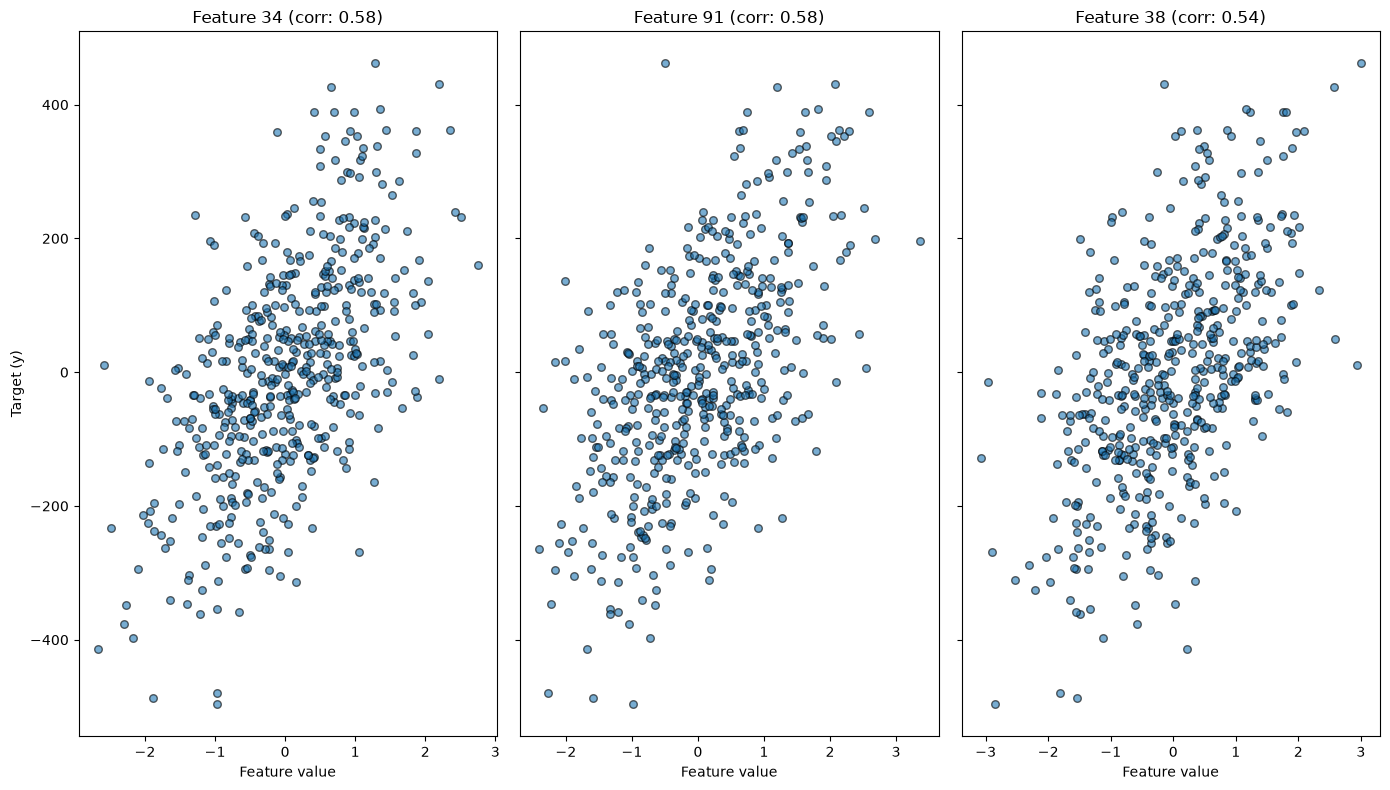

In [3]:
correlations = [np.corrcoef(X[:, i], y)[0, 1] for i in range(X.shape[1])]

top_features = np.argsort(np.abs(correlations))[::-1][:3]

fig, axes = plt.subplots(1, 3, sharey=True, figsize=(14, 8))
for idx, feat_idx in enumerate(top_features):
    ax = axes.flatten()[idx]
    ax.scatter(X[:, feat_idx], y, alpha=0.6, edgecolor='k', s=30)
    ax.set_title(f'Feature {feat_idx} (corr: {correlations[feat_idx]:.2f})')
    ax.set_xlabel('Feature value')
    if idx % 3 == 0:
        ax.set_ylabel('Target (y)')

plt.tight_layout()
plt.show()

### Train-Test Split
To evaluate the generalization performance of our models on unseen data, we partition the dataset into training (80%, 400 samples) and testing (20%, 100 samples) subsets using `train_test_split` with a fixed random seed (`random_state=42`) to ensure reproducibility.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)

print(f'Shape of X train: {X_train.shape}\nShape of y train: {y_train.shape}\nShape of X test: {X_test.shape}\nShape of y test: {y_test.shape}\n')

Shape of X train: (400, 100)
Shape of y train: (400,)
Shape of X test: (100, 100)
Shape of y test: (100,)



## Gradient Boosted Decision Trees (GBDT): Implementation from Scratch

In this section, we transition from parallel bagging ensembles (like Random Forest) to sequential boosting architectures by implementing a **Gradient Boosting Regressor** in pure NumPy. Unlike Random Forest, which reduces variance by averaging independent, deep trees, Gradient Boosting sequentially minimizes both bias and variance by training shallow trees to iteratively correct the residual errors of the preceding ensemble.

### 1. Adapting the CART Architecture for Regression (`MyDecisionTreeRegressor`)
To serve as the base weak learner for continuous targets, our previous `MyDecisionTree` classifier underwent several fundamental structural modifications:
* **Impurity Criterion (Variance Reduction):** Discrete classification metrics (Gini impurity and Entropy) were replaced with Mean Squared Error / variance (`np.var`). At each node, the algorithm searches for the feature and threshold $t$ that maximize **Variance Reduction** (implemented in `information_gain`), partitioning the data into maximally homogeneous numerical subsets.
* **Leaf Aggregation:** Instead of computing a majority-class vote or storing class probability dictionaries, terminal leaf nodes compute and return the arithmetic mean (`np.mean(y)`) of all target values falling into that region.
* **Continuous Stopping Criteria:** Because exact target equality (`len(np.unique(y)) == 1`) rarely holds for floating-point residuals, the base case now halts recursion when variance drops below a numerical tolerance (`np.var(y) <= 1e-5`), when `max_depth` is reached, or when the sample size falls below `min_samples_per_leaf`. Additionally, a safeguard (`max_ig <= 0`) prevents zero-gain splits from causing infinite recursion.
* **Regression Evaluation:** Classification methods (`predict_proba`, `accuracy`) were replaced with standard continuous metrics: Mean Squared Error (`mse_score`) and the coefficient of determination ($R^2$, `r_score`).

### 2. Sequential Residual Learning (`MyGradientBoosting`)
The `MyGradientBoosting` class orchestrates an additive ensemble of shallow regression trees (`max_depth=3` by default) to minimize the $L_2$ loss function $L(y, \hat{y}) = \frac{1}{2}(y - \hat{y})^2$:
* **Baseline Initialization (`fit`):** The model anchors its predictions with a constant initial estimate equal to the global target mean: $\hat{y}^{(0)} = \bar{y}$, which analytically minimizes initial MSE.
* **Pseudo-Residual Optimization:** Across $M$ boosting iterations (`n_estimators=50`), the algorithm computes the negative gradient of the $L_2$ loss with respect to the current ensemble predictions—which simplifies directly to the **residuals** $r^{(m)} = y - \hat{y}^{(m-1)}$. A new shallow `MyDecisionTreeRegressor` is then fitted directly to these residuals rather than the raw targets.
* **Shrinkage & Additive Inference (`predict`):** Each tree's correction is scaled by a `learning_rate` ($\eta = 0.1$) to prevent overfitting and stabilize convergence. During inference, the final prediction is reconstructed by starting from `self.base_pred` and sequentially summing the weighted outputs of all fitted trees:
  $$\hat{y}(X) = \bar{y} + \eta \sum_{m=1}^{M} r_m(X)$$

In [5]:
import numpy as np

class Node:
    def __init__(self, right_child=None, left_child=None, t=0, idx_feature=0, output_class=None):
        self.threshold = t
        self.idx_feature = idx_feature
        self.right_child = right_child
        self.left_child = left_child
        self.output_class = output_class        


class MyDecisionTreeRegressor:
    def __init__(self, max_depth=10, min_samples_per_leaf=5):
        self.max_depth = max_depth
        self.min_samples_per_leaf = min_samples_per_leaf
        self.root = None

    
    def mse(self, y):
        if len(y) == 0:
            return 0
        else:
            return np.var(y)
        

    def information_gain(self, y, y_left, y_right):

        if len(y_left) == 0 or len(y_right) == 0:
            return 0.0

        ig = self.mse(y) - (len(y_left)/len(y) * self.mse(y_left) + len(y_right)/len(y) * self.mse(y_right))

        return ig
        

    def build_tree(self, X, y, depth=0):
        n_features = X.shape[1]
        max_ig = 0
        best_t = 0

        if (depth >= self.max_depth) or (np.var(y) <= 1e-5) or (len(y) < self.min_samples_per_leaf):
            leaf_value = np.mean(y)

            return Node(output_class=leaf_value)
        
            
        for i in range(n_features):
            thresholds = np.unique(X[:,i])
            max_ig_feature = 0
            max_threshold = 0
                
            for t in thresholds:
                mask = X[:, i] < t
                y_left = y[mask]
                y_right = y[~mask]
                ig = self.information_gain(y, y_left, y_right)
                if ig > max_ig_feature:
                    max_ig_feature = ig
                    max_threshold = t
    
            if max_ig_feature > max_ig:
                max_ig = max_ig_feature
                max_feature = i
                best_t = max_threshold

        if max_ig <= 0:
            return Node(output_class=np.mean(y))

        best_mask = X[:, max_feature] < best_t

        X_left = X[best_mask]
        y_left = y[best_mask]
        X_right = X[~best_mask]
        y_right = y[~best_mask]

        left_child = self.build_tree(X_left, y_left, depth=depth+1)
        right_child = self.build_tree(X_right, y_right, depth=depth+1)

        return Node(right_child=right_child, left_child=left_child, idx_feature=max_feature, t=best_t)
            

    def fit(self, X, y):
        self.root = self.build_tree(X, y)


    def traverse_tree(self, x, node):
        if node.output_class is not None:
            return node.output_class

        if x[node.idx_feature] < node.threshold:
            return self.traverse_tree(x, node.left_child)
        else:
            return self.traverse_tree(x, node.right_child)
        
    

    def predict(self, X):
        y_preds = np.zeros(len(X))

        for i in range(len(X)):
            y_preds[i] = self.traverse_tree(X[i], self.root)

        return y_preds   


    def r_score(self, X, y):
        y_preds = self.predict(X)
        ss_res = np.sum((y_preds - y)**2)
        ss_tot = np.sum((np.mean(y) - y)**2)
        return 1 - ss_res / ss_tot
        

    def mse_score(self, X, y):
        y_preds = self.predict(X)
        mse = np.mean((y_preds - y)**2)
        return mse
    

In [6]:
class MyGradientBoosting:
    def __init__(self, n_estimators=50, learning_rate=1e-1, max_depth=3):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.base_pred = 0
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        self.base_pred = np.mean(y)
        y_preds = np.full_like(y, self.base_pred, dtype=float)

        for m in range(self.n_estimators):
            r = y - y_preds
            model = MyDecisionTreeRegressor(max_depth=self.max_depth)
            model.fit(X, r)
            tree_preds = model.predict(X)
            y_preds = y_preds + self.learning_rate * tree_preds
            self.trees.append(model)
            
    def predict(self, X):
        preds = np.full(X.shape[0], self.base_pred, dtype=float)
        for tree in self.trees:
            preds += self.learning_rate * tree.predict(X)

        return preds
            

### Model Training & $R^2$ Evaluation
We instantiate `MyGradientBoosting` with its default hyperparameters (50 sequential estimators, `learning_rate=0.1`, and `max_depth=3`) and fit the ensemble to the training subset (`X_train`, `y_train`). Evaluating the model's predictions on the unseen test data (`X_test`) yields a coefficient of determination of **$R^2 = 0.93$**, demonstrating that our custom additive ensemble captures 93% of the target variance and generalizes effectively across the high-dimensional feature space.

In [7]:
my_gradient_boosting = MyGradientBoosting()
my_gradient_boosting.fit(X_train, y_train)

y_pred = my_gradient_boosting.predict(X_test)

In [8]:
from sklearn.metrics import r2_score

print(f'r2 = {r2_score(y_test, y_pred):.2f}')

r2 = 0.93


### Diagnostic Residual & Prediction Analysis

To thoroughly evaluate the regression behavior beyond aggregate metrics, we inspect two diagnostic plots on the unseen test set:

* **Actual vs. Predicted (`R² = 0.93`):** The vast majority of test observations cluster tightly along the red dashed identity line ($y = x$), confirming strong linear alignment between true and predicted values across the central distribution. Noticeably, at the extreme tails ($|y| > 300$), the predictions slightly under-shoot the true magnitudes (flattening slightly toward the mean). This is a classic, expected property of tree-based ensembles: because terminal leaves output local averages, decision trees cannot extrapolate beyond the target range observed in the training splits, and a finite number of boosting iterations with shrinkage ($\eta = 0.1$) leaves a small residual bias at the boundaries.
* **Residuals vs. Predicted:** Plotting the prediction errors ($y_{\text{test}} - y_{\text{pred}}$) against predicted values reveals that the residuals are largely centered around the zero-error reference line without severe non-linear curvature. The slight upward tilt at the far right and downward dip at the far left directly mirror the shrinkage bias at the distribution tails noted above, indicating that adding more boosting estimators (`n_estimators`) would further absorb this remaining tail variance.

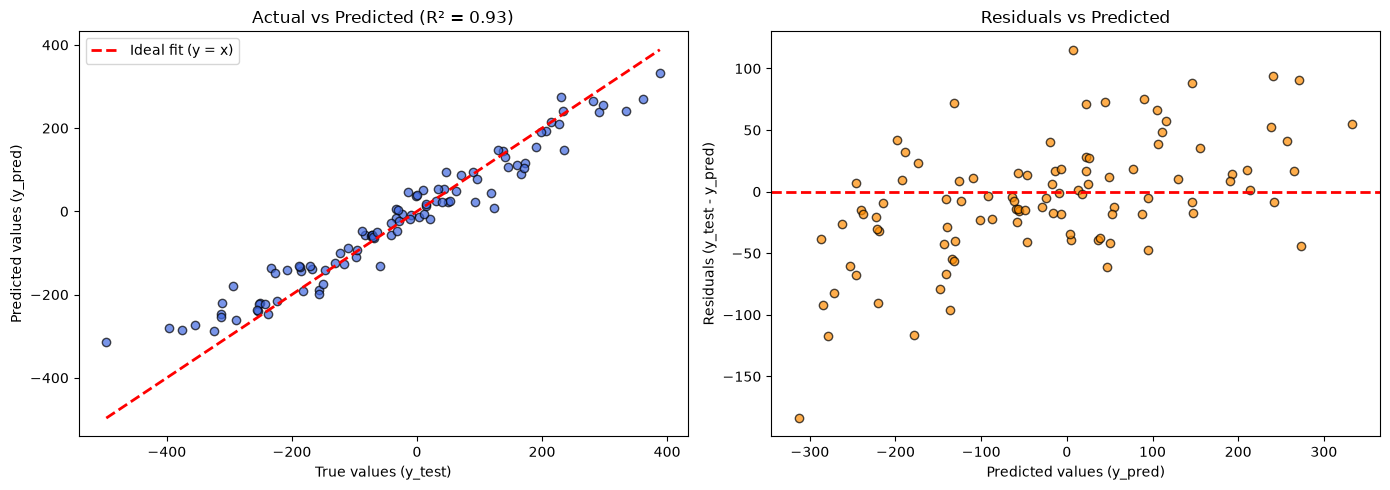

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.7, edgecolor='k', color='royalblue')
min_val, max_val = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal fit (y = x)')
axes[0].set_title(f'Actual vs Predicted (R² = {r2_score(y_test, y_pred):.2f})')
axes[0].set_xlabel('True values (y_test)')
axes[0].set_ylabel('Predicted values (y_pred)')
axes[0].legend()

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.7, edgecolor='k', color='darkorange')
axes[1].axhline(0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residuals vs Predicted')
axes[1].set_xlabel('Predicted values (y_pred)')
axes[1].set_ylabel('Residuals (y_test - y_pred)')

plt.tight_layout()
plt.show()